In [ ]:
!pip install --upgrade numba librosa

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# biblioteca para trabalhar com áudio
import librosa
import librosa.display

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
def generate_audio(anomally=False, duration=2.0, sr=22050):
  t = np.linspace(0, duration, int(sr * duration))
  f0 = np.random.uniform(118, 112)
  signal = 0.5 * np.sin(2 * np.pi * f0 * t) + 0.2 * np.sin(2 * np.pi * 2 * f0 * t)
  signal += 0.05 * np.random.randn(len(t))

  if(anomally):
    f_anomally = np.random.uniform(2500, 3500)
    error = 0.3 * np.sin(2 * np.pi * f_anomally * t) * np.exp(-3 * (t % 0.5))
    signal += error

  return signal, sr


In [ ]:
ok_signals_amount = 80
nok_signals_amount = 20

In [ ]:
# gera a quantidade desejada de áudios ok e não ok
ok_signals = [generate_audio(anomally=False) for _ in range(ok_signals_amount) ]
nok_signals = [generate_audio(anomally=True) for _ in range(nok_signals_amount) ]

In [ ]:
# transforma o áudio recebido em um espectograma mel
def create_spectrogram(audio, sr):
  spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
  spec_db = librosa.power_to_db(spec, ref=np.max)
  signature = np.mean(spec_db, axis=1)
  return signature, spec_db

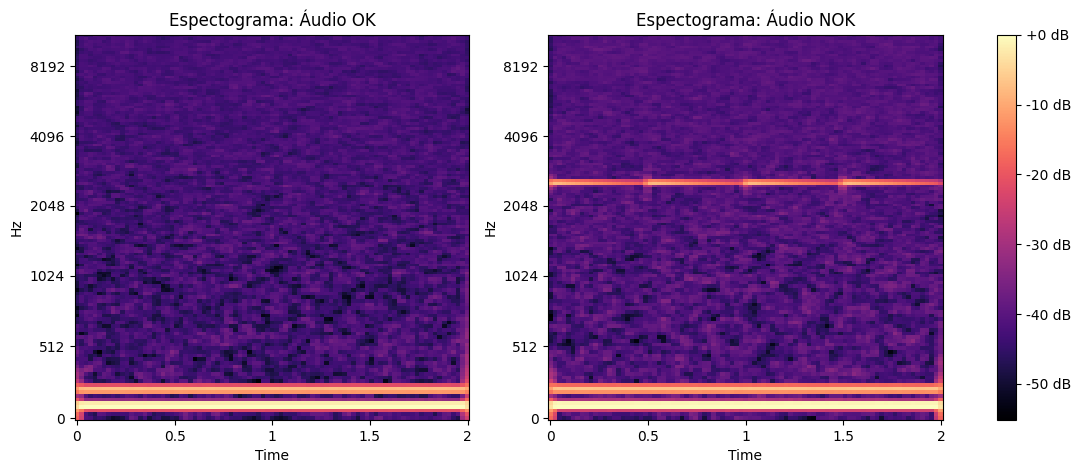

In [ ]:
# apenas para visualização se o espectograma está sendo gerado corretamente
ok_signature, ok_spec = create_spectrogram(*ok_signals[0])
nok_signature, nok_spec = create_spectrogram(*nok_signals[0])

fig, ax = plt.subplots(1,2,figsize=(14,5))
librosa.display.specshow(ok_spec, sr=ok_signals[0][1], x_axis='time', y_axis='mel',
                         ax=ax[0], cmap='magma')
ax[0].set_title('Espectograma: Áudio OK')

librosa.display.specshow(nok_spec, sr=ok_signals[0][1], x_axis='time', y_axis='mel',
                         ax=ax[1], cmap='magma')
ax[1].set_title('Espectograma: Áudio NOK')
plt.colorbar(ax[1].collections[0], format='%+2.0f dB', ax=ax)
plt.show()